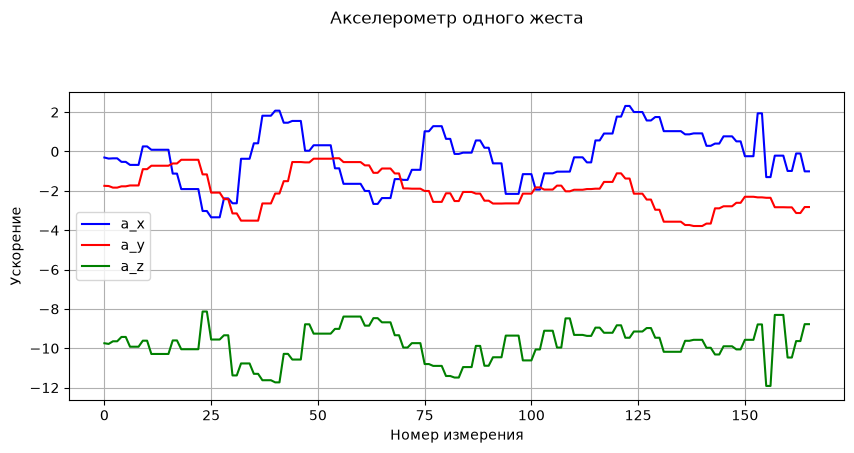

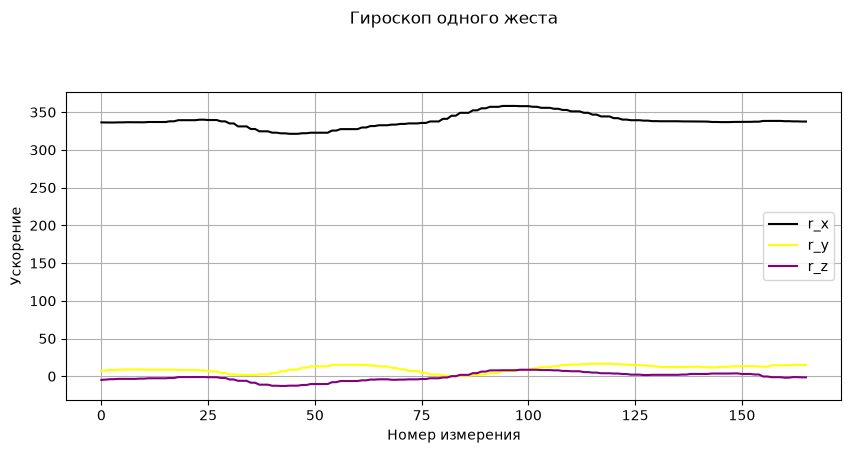

In [129]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import buttord, butter, sosfiltfilt
import pandas as pd
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from sklearn.decomposition import PCA
#import scipy
#import sklearn
#import pywt

# создаем путь к нашему датасету
dataset_path = Path(r"C:\Users\Даниил\IIT\task_1\data_legitimate\kovalexal\inf\train")

# получаем список всех текстовых файлов одного пользователя для тренировки 
txt_files = sorted(list(dataset_path.glob("*.txt")))

# функция парсинга тренировочного жеста из файла с номером num_file
# возвращает матрицу измерений (сигналов по горизонтали и временных рядов атрибутов по вертикали)
def get_training_gesture_txt(txt_files, num_file):
    
    # прочтали текстовый 0-ой файл как json-файл и записали его в виде словаря в file_data
    with open(txt_files[num_file], "r", encoding = "utf-8") as file:
        file_data = json.load(file)
    
    # обращаемся к словарю по двум ключам и получаем все измерения
    measurements = file_data["params"]["data"]
    
    # создаем матрицу измерений размера (кол-во измерений) * 6
    time_series_matrix_list = []
    for measurement in measurements:
        acceleration = measurement["acceleration"]
        rotation = measurement["rotation"]
        # связываем конец первого и начало второго списков
        time_series = acceleration + rotation
        time_series_matrix_list.append(time_series)
    
    # преобразование типов из списка в numpy матричный класс
    time_series_matrix = np.array(time_series_matrix_list, dtype=float)
    return time_series_matrix

# парсим атрибуты (временные ряды) из матрицы для 0-ого файла
time_series_matrix = get_training_gesture_txt(txt_files, 0)
a_x = time_series_matrix[:, 0]
a_y = time_series_matrix[:, 1]
a_z = time_series_matrix[:, 2]

r_x = np.unwrap(time_series_matrix[:, 3], period=360, axis=0)
r_y = np.unwrap(time_series_matrix[:, 4], period=360, axis=0)
r_z = np.unwrap(time_series_matrix[:, 5], period=360, axis=0)

# строим график временных рядов a_x, a_y, a_z (акселерометр)
plt.figure(figsize=(10, 4))

plt.plot(a_x, label="a_x", color="blue")
plt.plot(a_y, label="a_y", color="red")
plt.plot(a_z, label="a_z", color="green")

plt.title("Акселерометр одного жеста\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()

# строим график временных рядов r_x, r_y, r_z (гироскоп)
plt.figure(figsize=(10, 4))

plt.plot(r_x, label="r_x", color="black")
plt.plot(r_y, label="r_y", color="yellow")
plt.plot(r_z, label="r_z", color="purple")

plt.title("Гироскоп одного жеста\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()

Пытаюсь отфильтровать все 6 временных рядов в одном жесте (фильтр Баттерворта) и построить график для атрибута a_x

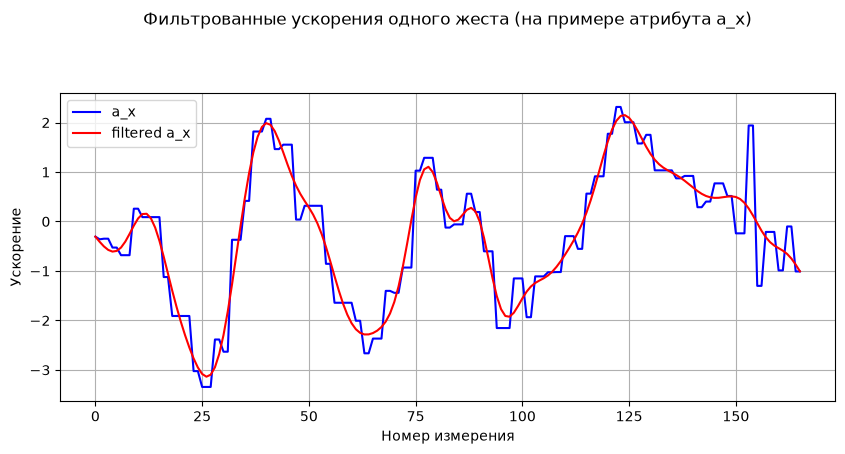

In [54]:
def butterworth_filter_gesture(time_series_matrix):
    wp = 0.17
    ws = 0.30
    gpass = 1
    gstop = 30

    order, cutoff = buttord(wp, ws, gpass, gstop)
    sos = butter(order, cutoff, btype="low", output="sos")
    filtered_matrix = sosfiltfilt(sos, time_series_matrix, axis=0)

    return filtered_matrix

filtered_time_series_matrix = butterworth_filter_gesture(time_series_matrix)
# строим график временных рядов a_x
plt.figure(figsize=(10, 4))

plt.plot(time_series_matrix[:, 0], label="a_x", color="blue")
plt.plot(filtered_time_series_matrix[:, 0], label="filtered a_x", color="red")

plt.title("Фильтрованные ускорения одного жеста (на примере атрибута a_x)\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()


Построим графики всех временных рядов одного пользователя

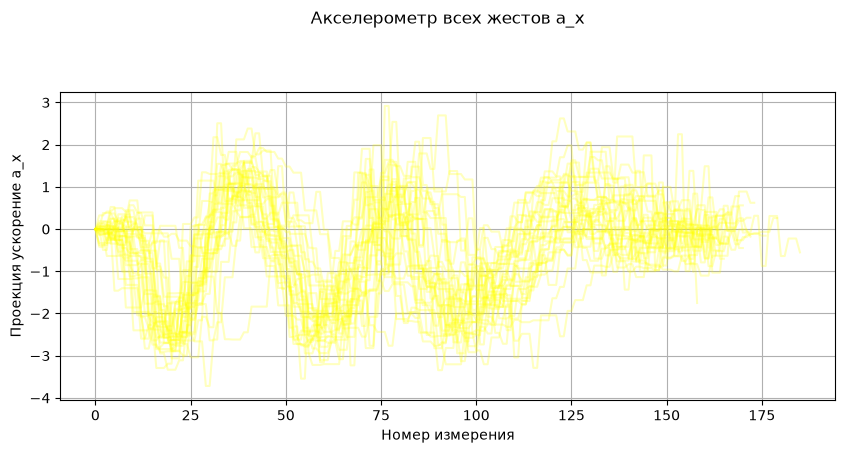

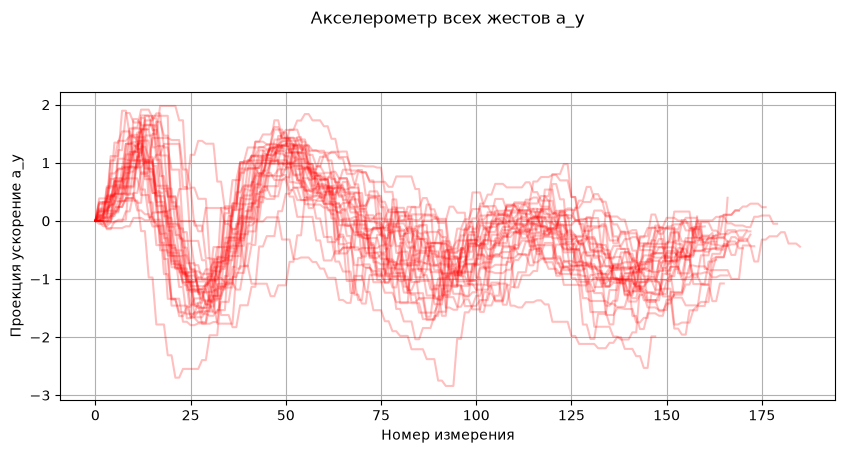

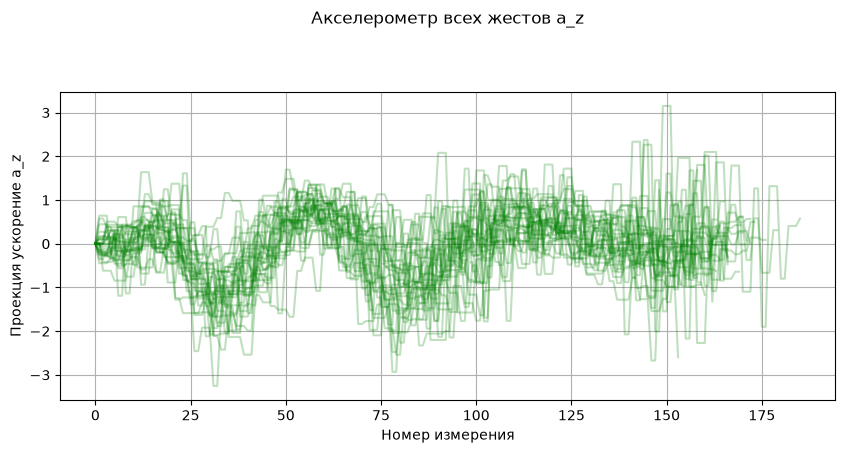

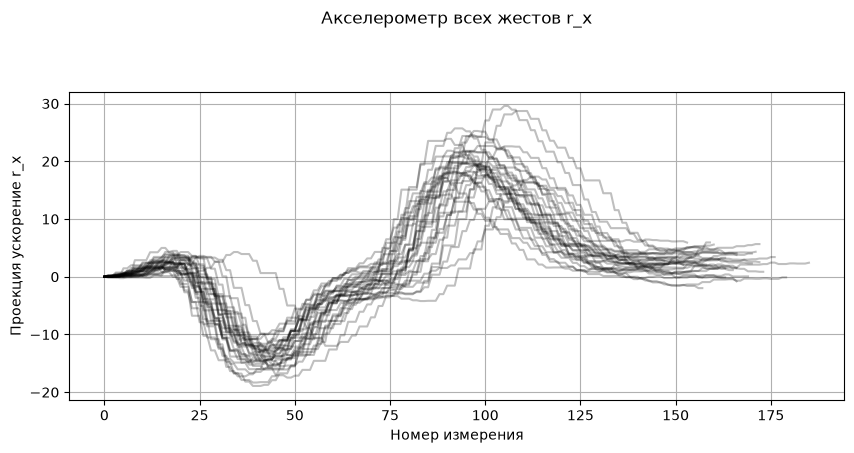

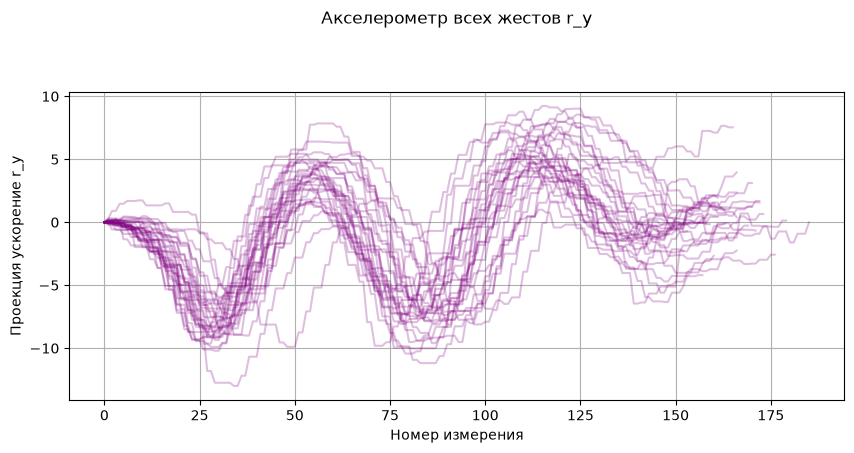

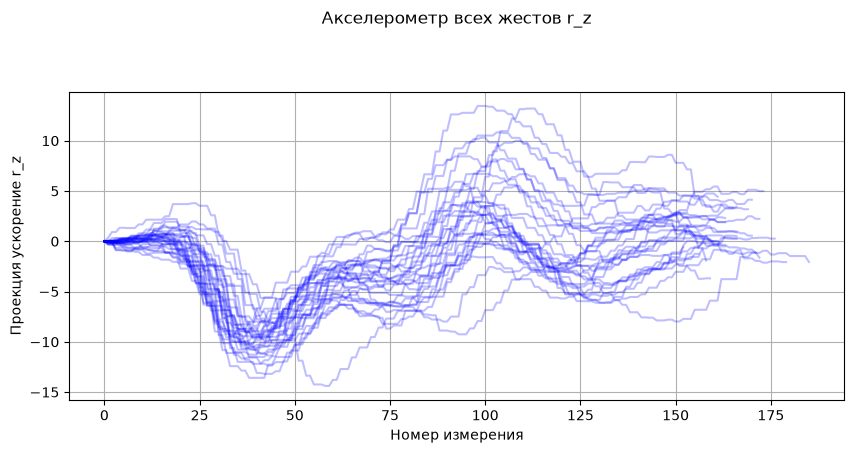

In [93]:
# функция приведения значений угла/угловой скорости r_x к общему типу
def prepare_rotation_angle(rotation_degrees):
    # приводим r_x к [-180;180]
    signed_angle = ((rotation_degrees + 180) % 360) - 180
    # вычитаем начальную ориентацию
    relative_rotations = signed_angle - signed_angle[0]
    return relative_rotations

# функция полной фильтрации жеста
def full_filt_gesture(txt_files, num_file, amount_all_attributes, filt):
    # парсим атрибуты (временные ряды) из матрицы для i-ого файла
    time_series_matrix = get_training_gesture_txt(txt_files, num_file)
    for i in range(amount_all_attributes):
        attribute = prepare_rotation_angle(time_series_matrix[:, i])
        # если фильтрация нужна
        if filt != 0: attribute = butterworth_filter_gesture(attribute)
        time_series_matrix[:, i] = attribute
    return time_series_matrix
    
# функция построения графика одной проекций (атрибута/временного ряда) для всех жестов
def build_one_attribute_plot(txt_files, dataset_path, num_time_series, filt):
    plt.figure(figsize=(10, 4))
    match num_time_series:
        case 0:
            attribute_name = "a_x"
            color_name = "yellow"
        case 1:
            attribute_name = "a_y"
            color_name = "red"
        case 2:
            attribute_name = "a_z"
            color_name = "green"
        case 3:
            attribute_name = "r_x"
            color_name = "black"
        case 4:
            attribute_name = "r_y"
            color_name = "purple"
        case 5:
            attribute_name = "r_z"
            color_name = "blue"
        
    for i in range(len(txt_files)):
        # парсим атрибуты (временные ряды) из матрицы для i-ого файла
        time_series_matrix = get_training_gesture_txt(dataset_path, i)
        # если фильтрация не нужна
        if filt == 0:
            attribute = prepare_rotation_angle(time_series_matrix[:, num_time_series])
            plt.plot(attribute, label=attribute_name, color=color_name, alpha=0.25)
        # если фильтрация нужна
        else:
            attribute = butterworth_filter_gesture(prepare_rotation_angle(time_series_matrix[:, num_time_series]))
            plt.plot(attribute, label=attribute_name, color=color_name, alpha=0.25)

    plt.title("Акселерометр всех жестов " + attribute_name + "\n\n\n")
    plt.xlabel("Номер измерения")
    plt.ylabel("Проекция ускорение " + attribute_name)
    plt.grid(True)
    
    plt.show()

# непосредственно строим все графики
amount_all_attributes = 6
for i in range(amount_all_attributes):
    build_one_attribute_plot(txt_files, dataset_path, i, filt=0)

Применим реализованный фильтр Баттерворта ко всем этим рядам

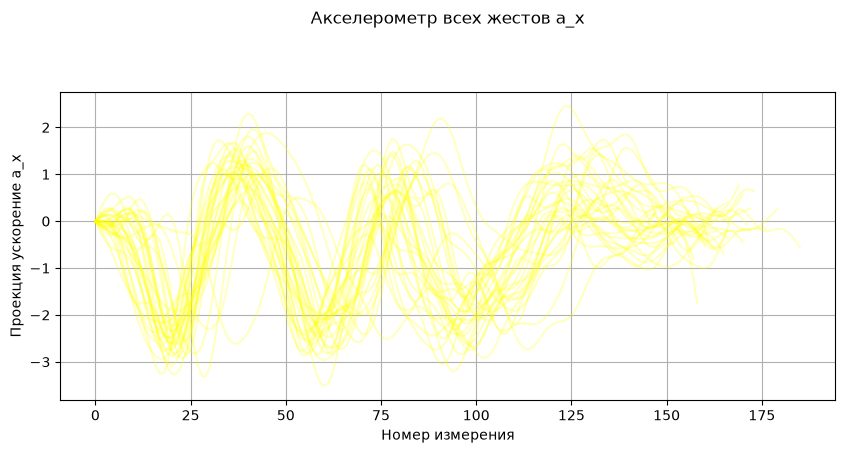

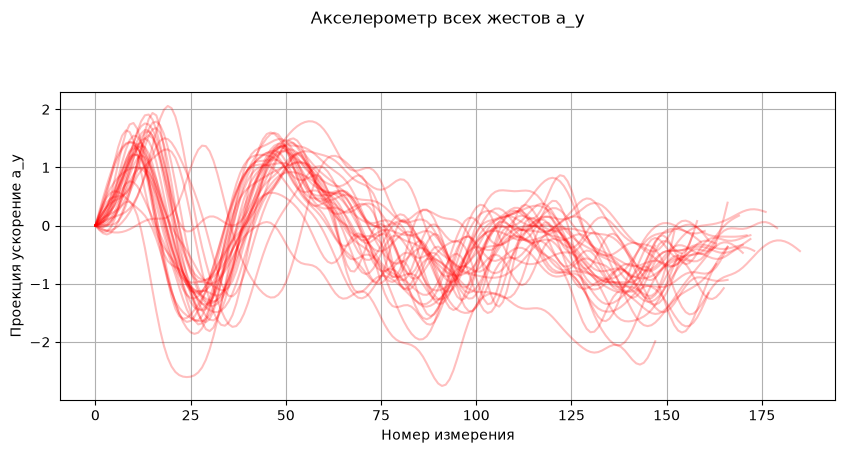

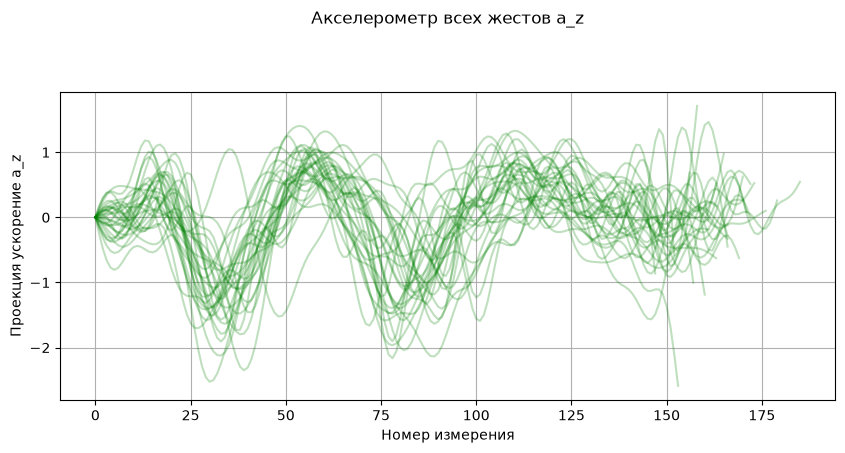

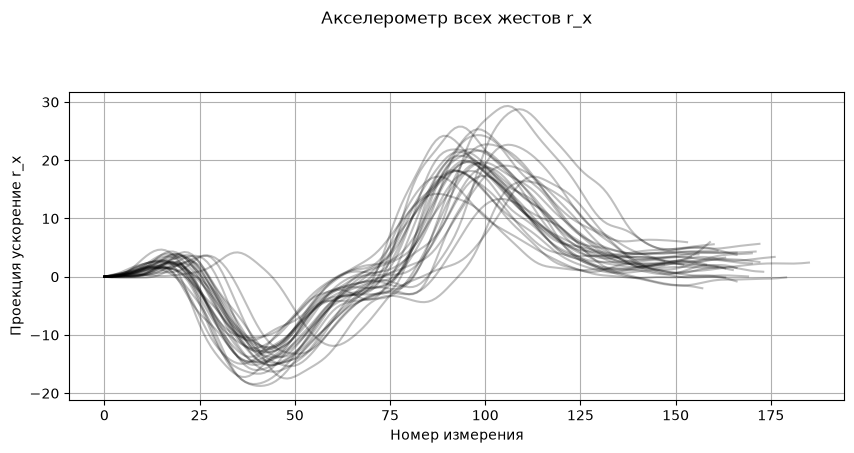

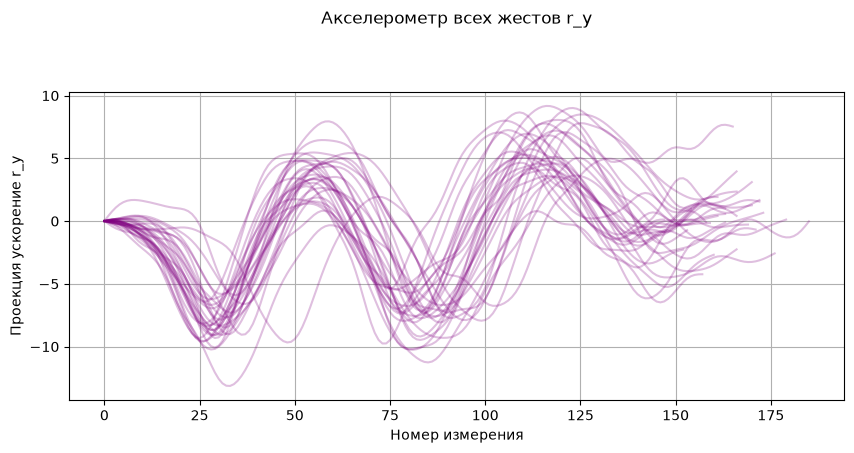

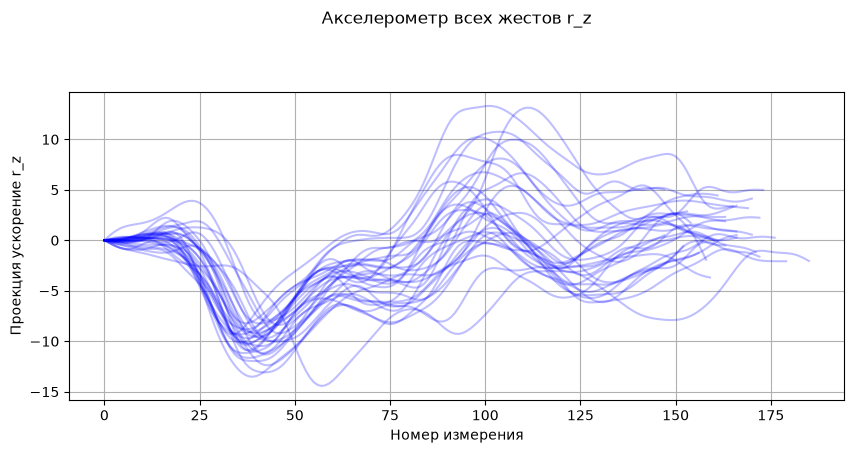

In [81]:
for i in range(amount_all_attributes):
    build_one_attribute_plot(txt_files, dataset_path, i, filt=1)

Создаем таблицу для обучения модели: 30 жестов x 42 признака
42 признака = 6 временных рядов x 7 статистик
ститистика - среднее/медиана/мода/квантиль и д.р. Это то, что используется для описания примерного поведения ряда

In [141]:
def extract_features(processed_gesture):
    mean_values = np.mean(processed_gesture, axis=0)
    std_values = np.std(processed_gesture,axis=0)
    min_values = np.min(processed_gesture,axis=0)
    max_values = np.max(processed_gesture,axis=0)
    median_values = np.median(processed_gesture,axis=0)
    q1_values = np.percentile(processed_gesture, 25,axis=0)
    q3_values = np.percentile(processed_gesture,75,axis=0)

    features = np.concatenate([
        mean_values,
        std_values,
        min_values,
        max_values,
        median_values,
        q1_values,
        q3_values
    ])

    return features

# создаем матрицу 42-ух признаков для одного жеста
filtered_gesture = full_filt_gesture(
    txt_files,
    num_file=0,
    amount_all_attributes=6,
    filt=True,
)
features = extract_features(filtered_gesture)

# создаем имена признаков = (имя статистики) * (имя атрибута)
attribute_names = ["a_x", "a_y", "a_z", "r_x", "r_y", "r_z"]
statistic_names = ["mean", "std", "min", "max", "median", "q1", "q3"]
feature_names = []

for statistic_name in statistic_names:
    for attribute_name in attribute_names:
        feature_name = (statistic_name + "_" + attribute_name)
        feature_names.append(feature_name)

# получаем матрицу из векторов признаков по всем жестам: (30 жестов)*(42 признака)
feature_rows = []
feature_rows_no_filt = []
gesture_file_names = []
for i in range(len(txt_files)):
    # читаем один жест
    time_series_matrix = get_training_gesture_txt(txt_files, i)

    # подготавливаем углы и фильтруем
    filtered_gesture = full_filt_gesture(
        txt_files,
        num_file=i,
        amount_all_attributes=6,
        filt=True,
    )

    # получаем 42 признака
    features = extract_features(filtered_gesture)

    # добавляем строку в будущую таблицу
    feature_rows.append(features)
    
    # названия строк - имена файлов с жестами
    gesture_file_names.append(txt_files[i].name)

# создаем красивую табличку с признаками по жестам
features_table = pd.DataFrame(feature_rows, index=gesture_file_names, columns=feature_names)
features_table.index.name = "gesture_file"

# показываем все признаки по первым 5-ти жестам
pd.set_option("display.max_columns", None)
display(features_table.head())

# превращаем таблицу жестов-признаков в обычную numpy матрицу
X_train = features_table.to_numpy(dtype=float)

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z
gesture_file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1423911297287.txt,0.051516,-0.225990,-0.050792,2.204940,2.588740,4.022665,1.290210,0.941957,0.724682,9.438174,4.664962,5.631605,-2.830248,-2.057467,-1.795888,-14.860336,-7.148716,-7.967980,2.456292,1.378999,1.319845,21.906234,9.175121,13.306588,0.199783,-0.239501,0.000768,1.313309,3.958642,3.597985,-0.839429,-0.891216,-0.351266,-1.658181,-0.358285,0.517057,0.907863,0.466616,0.548346,4.303643,6.391912,8.163344
1423911305331.txt,0.124160,-0.307725,0.048974,0.047656,0.486862,1.689126,1.285124,0.876333,0.581616,8.697341,4.449094,5.205486,-3.307971,-1.741593,-1.591147,-17.476720,-7.939762,-8.396959,2.189328,2.057045,1.199871,16.390300,7.808571,13.138278,0.092795,-0.292769,0.138960,0.671228,0.552668,0.997951,-0.564969,-1.048764,-0.161013,-4.065099,-2.829203,-0.736986,1.180935,0.100330,0.437613,3.611726,4.288620,4.427562
1423911313082.txt,-0.344495,-1.390271,-0.238125,2.783716,-0.112020,1.623484,1.369636,0.866021,0.740325,11.569966,4.989951,4.963642,-3.255603,-2.757146,-2.039466,-17.216936,-9.322255,-9.307568,1.668192,0.408295,1.287898,25.769627,8.662087,10.206941,-0.100929,-1.431190,-0.134613,1.955881,-0.217352,0.882899,-1.431621,-2.104609,-0.512023,-3.566668,-3.967568,-0.791544,0.959205,-0.734481,0.188286,9.572824,4.408086,5.026533
1423911320348.txt,-0.184699,-0.200525,-0.017725,1.900038,0.321227,2.037365,1.248572,0.755844,0.612697,10.460139,4.670203,5.330379,-2.476452,-1.519946,-1.635287,-18.422642,-9.087338,-10.971848,1.737681,1.440306,0.948065,22.731369,8.062490,10.748580,0.025901,-0.249500,0.121442,2.316195,0.952515,2.233866,-1.346977,-0.785049,-0.220875,-2.848269,-2.594355,-0.063255,0.754499,0.291223,0.413413,5.340747,3.904952,5.200012
1423911329566.txt,-0.357731,-0.466115,-0.185987,1.379524,0.133137,0.480476,1.179662,0.708193,0.581911,10.943586,4.498693,4.715370,-2.828773,-1.728723,-1.389573,-18.751335,-8.292559,-9.094444,1.323747,1.001415,0.926216,22.663468,7.095347,9.963352,-0.071029,-0.536876,-0.175577,1.583239,0.100692,1.268531,-1.478448,-1.043734,-0.477860,-4.318662,-3.357866,-2.623564,0.725995,0.044952,0.224044,7.462263,4.009821,2.351514


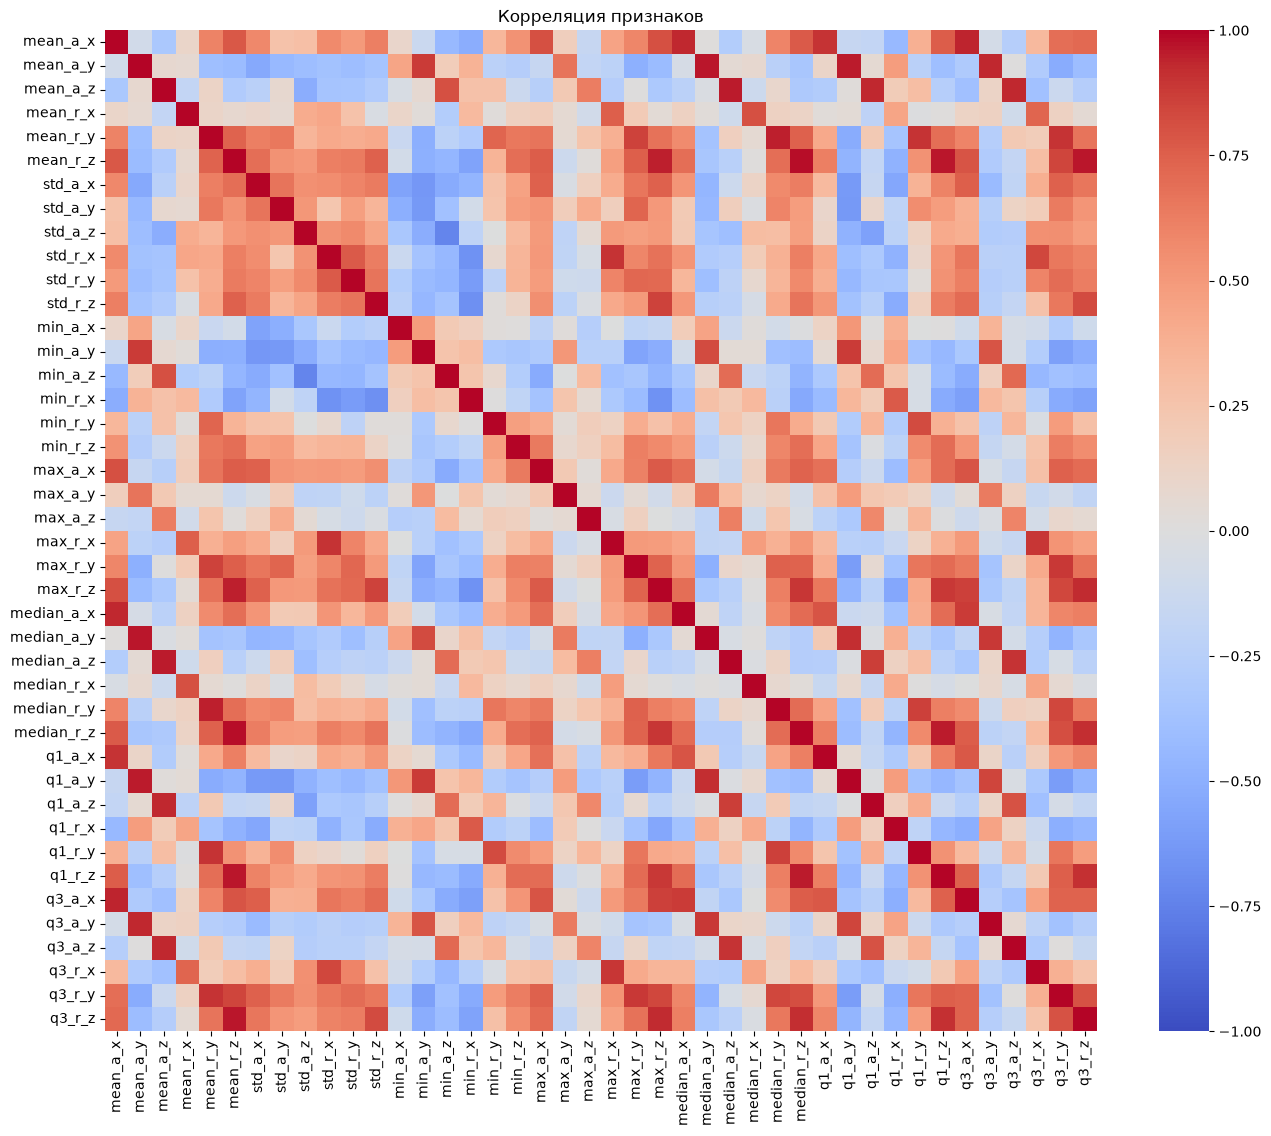

mean_r_z    median_r_z    0.977603
            q1_r_z        0.968081
mean_a_y    median_a_y    0.967833
mean_r_z    q3_r_z        0.964995
mean_a_z    median_a_z    0.958836
median_r_z  q1_r_z        0.956875
mean_a_y    q1_a_y        0.953678
mean_r_y    median_r_y    0.952948
mean_r_z    max_r_z       0.950142
mean_a_x    q3_a_x        0.939840
mean_a_y    q3_a_y        0.936259
mean_a_x    median_a_x    0.935110
mean_a_z    q1_a_z        0.934951
            q3_a_z        0.931548
max_r_z     q3_r_z        0.922617
median_r_z  q3_r_z        0.920357
median_a_y  q1_a_y        0.917484
q1_r_z      q3_r_z        0.910568
median_a_z  q3_a_z        0.905992
mean_r_y    q1_r_y        0.904612
mean_a_x    q1_a_x        0.903403
mean_r_y    q3_r_y        0.900507
dtype: float64

In [140]:
# строим матрицу корреляций
correlation = features_table.corr()

plt.figure(figsize=(16, 13))

sns.heatmap(correlation, cmap="coolwarm", center=0, vmin=-1, vmax=1)

plt.title("Корреляция признаков")
plt.show()

upper_triangle = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))

strong_pairs = upper_triangle.stack()
strong_pairs = strong_pairs[strong_pairs.abs() > 0.9]

display(strong_pairs.sort_values(key=abs, ascending=False))

                                    Стандартизация
Стандартизация показывает на сколько стандартных отклонений значение отклонилось от среднего. Она нужна для того, чтобы сделать данные независимыми от их единиц измерения, т.е. относительными друг от друга





In [122]:
# создаем объект scaler
scaler = StandardScaler()
# вычисляем для каждого столбца (признака) среднее и стандартное отклонение
scaler.fit(X_train)
# стандартизируем признаки 
X_train_scaled = scaler.transform(X_train)

# выводим стандартизированные признаки для первых 5-ти жестов
scaled_features_table = pd.DataFrame(
    X_train_scaled,
    index=features_table.index,
    columns=features_table.columns
)
print('\n\n', "                                              Б Ы Л О")
display(features_table.head())
print('\n\n',"                                              С Т А Л О")
display(scaled_features_table.head())



                                               Б Ы Л О


,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z
gesture_file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1423911297287.txt,0.051516,-0.225990,-0.050792,2.204940,2.588740,4.022665,1.290210,0.941957,0.724682,9.438174,4.664962,5.631605,-2.830248,-2.057467,-1.795888,-14.860336,-7.148716,-7.967980,2.456292,1.378999,1.319845,21.906234,9.175121,13.306588,0.199783,-0.239501,0.000768,1.313309,3.958642,3.597985,-0.839429,-0.891216,-0.351266,-1.658181,-0.358285,0.517057,0.907863,0.466616,0.548346,4.303643,6.391912,8.163344
1423911305331.txt,0.124160,-0.307725,0.048974,0.047656,0.486862,1.689126,1.285124,0.876333,0.581616,8.697341,4.449094,5.205486,-3.307971,-1.741593,-1.591147,-17.476720,-7.939762,-8.396959,2.189328,2.057045,1.199871,16.390300,7.808571,13.138278,0.092795,-0.292769,0.138960,0.671228,0.552668,0.997951,-0.564969,-1.048764,-0.161013,-4.065099,-2.829203,-0.736986,1.180935,0.100330,0.437613,3.611726,4.288620,4.427562
1423911313082.txt,-0.344495,-1.390271,-0.238125,2.783716,-0.112020,1.623484,1.369636,0.866021,0.740325,11.569966,4.989951,4.963642,-3.255603,-2.757146,-2.039466,-17.216936,-9.322255,-9.307568,1.668192,0.408295,1.287898,25.769627,8.662087,10.206941,-0.100929,-1.431190,-0.134613,1.955881,-0.217352,0.882899,-1.431621,-2.104609,-0.512023,-3.566668,-3.967568,-0.791544,0.959205,-0.734481,0.188286,9.572824,4.408086,5.026533
1423911320348.txt,-0.184699,-0.200525,-0.017725,1.900038,0.321227,2.037365,1.248572,0.755844,0.612697,10.460139,4.670203,5.330379,-2.476452,-1.519946,-1.635287,-18.422642,-9.087338,-10.971848,1.737681,1.440306,0.948065,22.731369,8.062490,10.748580,0.025901,-0.249500,0.121442,2.316195,0.952515,2.233866,-1.346977,-0.785049,-0.220875,-2.848269,-2.594355,-0.063255,0.754499,0.291223,0.413413,5.340747,3.904952,5.200012
1423911329566.txt,-0.357731,-0.466115,-0.185987,1.379524,0.133137,0.480476,1.179662,0.708193,0.581911,10.943586,4.498693,4.715370,-2.828773,-1.728723,-1.389573,-18.751335,-8.292559,-9.094444,1.323747,1.001415,0.926216,22.663468,7.095347,9.963352,-0.071029,-0.536876,-0.175577,1.583239,0.100692,1.268531,-1.478448,-1.043734,-0.477860,-4.318662,-3.357866,-2.623564,0.725995,0.044952,0.224044,7.462263,4.009821,2.351514




                                               С Т А Л О


,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z
gesture_file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1423911297287.txt,1.910229,-0.008329,0.008339,-0.097232,2.574684,2.476589,1.569726,2.013712,1.281170,0.395087,1.194203,2.346967,-0.015512,-1.357982,-0.546652,-0.235382,1.200057,1.509877,2.536339,-0.263055,1.011535,0.374681,1.621650,2.230130,1.624426,0.206095,-0.134815,-0.614080,3.184279,2.171844,1.847951,-0.234904,0.118675,0.081193,2.290538,1.975824,1.502876,0.744437,0.669711,-0.799444,2.495961,2.972189
1423911305331.txt,2.152431,-0.305178,0.470153,-1.994386,0.977525,1.449378,1.529788,1.261659,-0.489709,-0.087383,0.795841,1.785535,-1.748363,-0.492922,-0.008012,-1.496158,0.634292,1.237490,1.916858,1.838559,0.522682,-1.117567,0.923181,2.186744,1.251847,0.015853,0.570024,-1.243896,0.736513,1.001565,2.737375,-0.709446,0.829727,-1.598103,0.497551,1.399026,2.184721,-0.668068,0.158568,-1.144835,1.233103,1.388395
1423911313082.txt,0.589876,-4.236794,-0.858828,0.411753,0.522451,1.420483,2.193350,1.143476,1.474799,1.783426,1.793939,1.466893,-1.558409,-3.274134,-1.187467,-1.370974,-0.354483,0.659284,0.707579,-3.271771,0.881364,1.419860,1.359429,1.431121,0.577220,-4.049930,-0.825320,0.016217,0.183124,0.949780,-0.071127,-3.889691,-0.482135,-1.250350,-0.328488,1.373932,1.631075,-3.887339,-0.992330,1.830824,1.304832,1.642330
1423911320348.txt,1.122655,0.084154,0.161407,-0.365369,0.851664,1.602671,1.242795,-0.119162,-0.104989,1.060647,1.203876,1.950087,1.267816,0.114084,-0.124136,-1.951976,-0.186467,-0.397477,0.868823,-0.073033,-0.503340,0.597908,1.052964,1.570741,1.018896,0.170385,0.480677,0.369649,1.023871,1.557852,0.203175,0.084875,0.605997,-0.749126,0.667965,1.708909,1.119939,0.068070,0.046860,-0.281743,1.002741,1.715877
1423911329566.txt,0.545745,-0.880423,-0.617480,-0.823118,0.708739,0.917337,0.701744,-0.665244,-0.486062,1.375494,0.887370,1.139782,-0.010163,-0.457678,0.522298,-2.110366,0.381968,0.794611,-0.091696,-1.433386,-0.592368,0.579538,0.558639,1.368330,0.681343,-0.855957,-1.034252,-0.349306,0.411692,1.123354,-0.222875,-0.694293,-0.354455,-1.775013,0.113934,0.531293,1.048766,-0.881621,-0.827271,0.777275,1.065706,0.508250
